In [24]:
import pandas as pd
import time
from selenium import webdriver
from webdriver_manager.chrome import ChromeDriverManager

In [25]:
# Create Driver
driver = webdriver.Chrome()

# Go to characters page
page_url = "https://breakingbad.fandom.com/wiki/Category:Breaking_Bad_Characters"
driver.get(page_url)

# Click on 'I Accept'
time.sleep(4)
driver.find_element(By.XPATH, '//button[text()="I Accept"]').click()

# Find Seasons
season_categories = driver.find_elements(By.XPATH, "//div[contains(text(), 'H')]/following::ul[1]//a[@class='category-page__member-link']")[:6]

seasons = []
for category in season_categories:
    season_url = category.get_attribute('href')
    season_name = category.text
    seasons.append({'season_name': season_name, "url": season_url})

In [26]:
seasons

[{'season_name': 'Category:Season 1 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_1_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 2 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_2_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 3 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_3_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 4 Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_4_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 5A Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_5A_Characters_(Breaking_Bad)'},
 {'season_name': 'Category:Season 5B Characters (Breaking Bad)',
  'url': 'https://breakingbad.fandom.com/wiki/Category:Season_5B_Characters_(Breaking_Bad)'}]

In [27]:
character_list = []

for season in seasons:
    # go to season page
    driver.get(season['url'])

    character_elems = driver.find_elements(By.CLASS_NAME, 'category-page__member-link')

    for elem in character_elems:
        character_list.append({'season': season['season_name'], 'character': elem.text})


In [28]:
pd.DataFrame(character_list)

,season,character
0,Category:Season 1 Characters (Breaking Bad),List of bit parts in Breaking Bad/Season 1
1,Category:Season 1 Characters (Breaking Bad),Hugo Archilleya
2,Category:Season 1 Characters (Breaking Bad),Badger
3,Category:Season 1 Characters (Breaking Bad),Dr. Belknap
4,Category:Season 1 Characters (Breaking Bad),Ben
...,...,...
373,Category:Season 5B Characters (Breaking Bad),Jack Welker
374,Category:Season 5B Characters (Breaking Bad),Holly White
375,Category:Season 5B Characters (Breaking Bad),Skyler White
376,Category:Season 5B Characters (Breaking Bad),Walter White


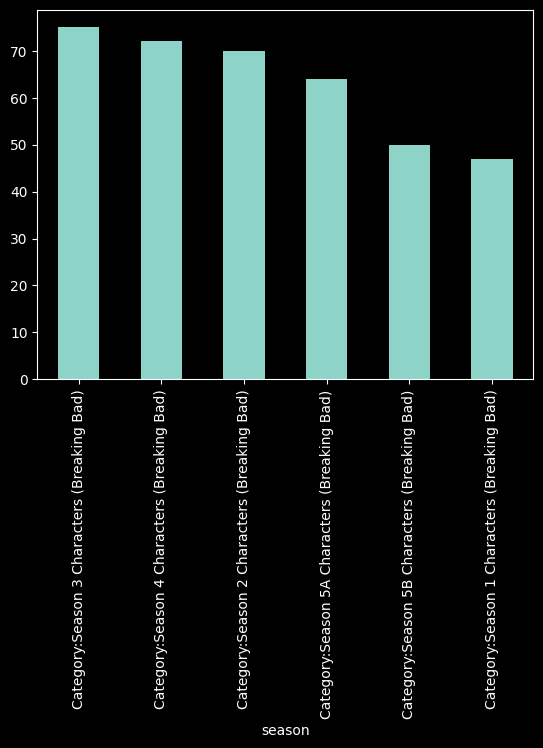

In [29]:
import matplotlib.pyplot as plt

character_df = pd.DataFrame(character_list)

character_df['season'].value_counts().plot(kind="bar")
plt.show()